In [2]:
import sys
import os

# Add the root directory to path so we can import from src
sys.path.append(os.path.abspath('..'))

import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

# Import your actual system components
# ⚠️ MAKE SURE THIS MATCHES YOUR ACTUAL CLASS NAME IN src/retriever/search_engine.py
from src.retriever.search_engine import SearchEngine 
# If your file is named indexer.py, change the line above to: from src.retriever.indexer import SearchEngine

print("✅ Libraries loaded successfully")

ModuleNotFoundError: No module named 'src'

In [2]:
# Cell 2: Load Data & Fix Paths
import os
import pickle
import pandas as pd

# Load Metadata
METADATA_PATH = '../artifacts/clean_metadata.pkl' # or metadata.pkl

with open(METADATA_PATH, 'rb') as f:
    metadata = pickle.load(f)

df = pd.DataFrame(metadata)

# 🛠️ FIX: Point to 'data/raw/images/'
def get_path(row):
    # This stores the path relative to the project root
    return f"data/raw/images/{row['id']}.jpg"

# Apply the fix to the dataframe
df['image_path'] = df.apply(get_path, axis=1)

# 🔍 VERIFY: Check if the first file actually exists from the notebook's perspective
# We use "../" because the notebook is in 'notebooks/', so we go up one level to root
first_id = df.iloc[0]['id']
test_path = f"../data/raw/images/{first_id}.jpg"

if os.path.exists(test_path):
    print(f"✅ SUCCESS! Found image at: {test_path}")
else:
    print(f"❌ STILL FAILED. Could not find: {test_path}")
    print("⚠️ Please double-check that your folders are exactly: StyleSage -> data -> raw -> images")

print(f"📊 Dataset Loaded: {len(df)} items")
df.head(3)

✅ SUCCESS! Found image at: ../data/raw/images/15970.jpg
📊 Dataset Loaded: 44441 items


,id,filename,productDisplayName,gender,masterCategory,subCategory,articleType,baseColour,season,usage,image_path
0,15970,15970.jpg,Turtle Check Men Navy Blue Shirt,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,Casual,data/raw/images/15970.jpg
1,39386,39386.jpg,Peter England Men Party Blue Jeans,Men,Apparel,Bottomwear,Jeans,Blue,Summer,Casual,data/raw/images/39386.jpg
2,59263,59263.jpg,Titan Women Silver Watch,Women,Accessories,Watches,Watches,Silver,Winter,Casual,data/raw/images/59263.jpg


In [3]:
df.shape

(44441, 11)

In [4]:
class SearchMetrics:
    @staticmethod
    def precision_at_k(retrieved_ids, relevant_ids, k):
        """Precision: % of retrieved items that are relevant"""
        top_k = retrieved_ids[:k]
        relevant = len(set(top_k) & set(relevant_ids))
        return relevant / k

    @staticmethod
    def recall_at_k(retrieved_ids, relevant_ids, k):
        """Recall: % of ALL relevant items that were found"""
        if len(relevant_ids) == 0: return 0.0
        top_k = retrieved_ids[:k]
        found = len(set(top_k) & set(relevant_ids))
        return found / len(relevant_ids)

    @staticmethod
    def reciprocal_rank(retrieved_ids, relevant_ids):
        """MRR: 1 / Position of first relevant item"""
        for i, item_id in enumerate(retrieved_ids):
            if item_id in relevant_ids:
                return 1.0 / (i + 1)
        return 0.0

In [5]:
def generate_test_set(df, samples_per_category=3):
    """
    Creates test queries based on 'Category + Color' combinations.
    Ground Truth = All other items with same Category & Color.
    """
    test_set = []
    
    # Define scenarios to test (Category, Color)
    scenarios = [
        ('Tshirts', 'Blue'), ('Tshirts', 'Black'),
        ('Shirts', 'White'), ('Jeans', 'Blue'),
        ('Casual Shoes', 'Brown'), ('Watches', 'Black'),
        ('Handbags', 'Red')
    ]
    
    for category, color in scenarios:
        # Filter dataframe
        subset = df[(df['articleType'] == category) & (df['baseColour'] == color)]
        
        if len(subset) < 5: continue # Skip if not enough data
            
        # Sample random items as queries
        samples = subset.sample(n=min(samples_per_category, len(subset)))
        
        for _, row in samples.iterrows():
            query_id = row['id']
            
            # Ground Truth: All items in this subset EXCEPT the query itself
            relevant_ids = subset[subset['id'] != query_id]['id'].tolist()
            
            test_set.append({
                'query_id': query_id,
                'image_path': row['image_path'],
                'description': f"{color} {category}",
                'relevant_ids': relevant_ids
            })
            
    print(f"✅ Generated {len(test_set)} test queries")
    return test_set

test_queries = generate_test_set(df)

✅ Generated 21 test queries


In [6]:
def visualize_search(query_data, retrieved_ids, scores, df):
    """
    Plots the Query Image vs. Top 5 Retrieved Results
    """
    # 1. Setup Plot
    fig, axes = plt.subplots(1, 6, figsize=(20, 4))
    
    # 2. Show Query Image
    query_path = f"../{query_data['image_path']}" # Adjust path relative to notebook
    try:
        axes[0].imshow(Image.open(query_path))
        axes[0].set_title(f"QUERY\n{query_data['description']}")
        axes[0].axis('off')
    except:
        axes[0].text(0.5, 0.5, "Image Not Found", ha='center')

    # 3. Show Results
    for i, item_id in enumerate(retrieved_ids[:5]):
        ax = axes[i+1]
        
        # Get metadata for this result
        item_row = df[df['id'] == item_id].iloc[0]
        img_path = f"../{item_row['image_path']}"
        
        try:
            ax.imshow(Image.open(img_path))
            
            # Check if it's a match (Ground Truth Check)
            is_match = item_id in query_data['relevant_ids']
            color = 'green' if is_match else 'red'
            status = "✅ Match" if is_match else "❌ Miss"
            
            ax.set_title(f"Rank #{i+1}\n{status}", color=color, fontweight='bold')
            ax.axis('off')
            
            # Add border
            for spine in ax.spines.values():
                spine.set_edgecolor(color)
                spine.set_linewidth(3)
                
        except Exception as e:
            ax.text(0.5, 0.5, "Img Error", ha='center')
            
    plt.tight_layout()
    plt.show()

⏳ Loading Search Engine...
✅ FAISS Index loaded: 44441 items
🔄 Converting Pandas DataFrame to List...
✅ Metadata loaded: 44441 items
🧠 Loading CLIP Model (openai/clip-vit-base-patch32)...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


✅ System Ready.
🚀 Starting Evaluation...


  0%|          | 0/21 [00:00<?, ?it/s]C:\Users\AMAND\AppData\Local\Temp\ipykernel_19752\746249868.py:44: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\AMAND\AppData\Local\Temp\ipykernel_19752\746249868.py:44: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\AMAND\projects\fashion-system\aienv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\AMAND\projects\fashion-system\aienv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


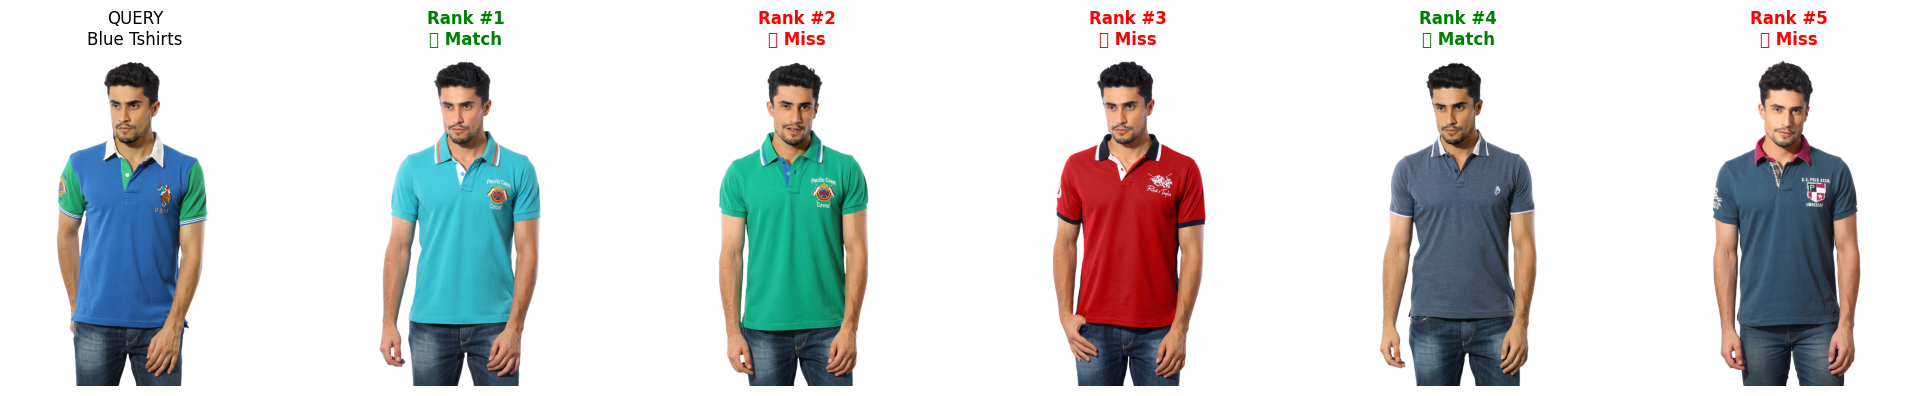

 24%|██▍       | 5/21 [00:04<00:07,  2.17it/s]

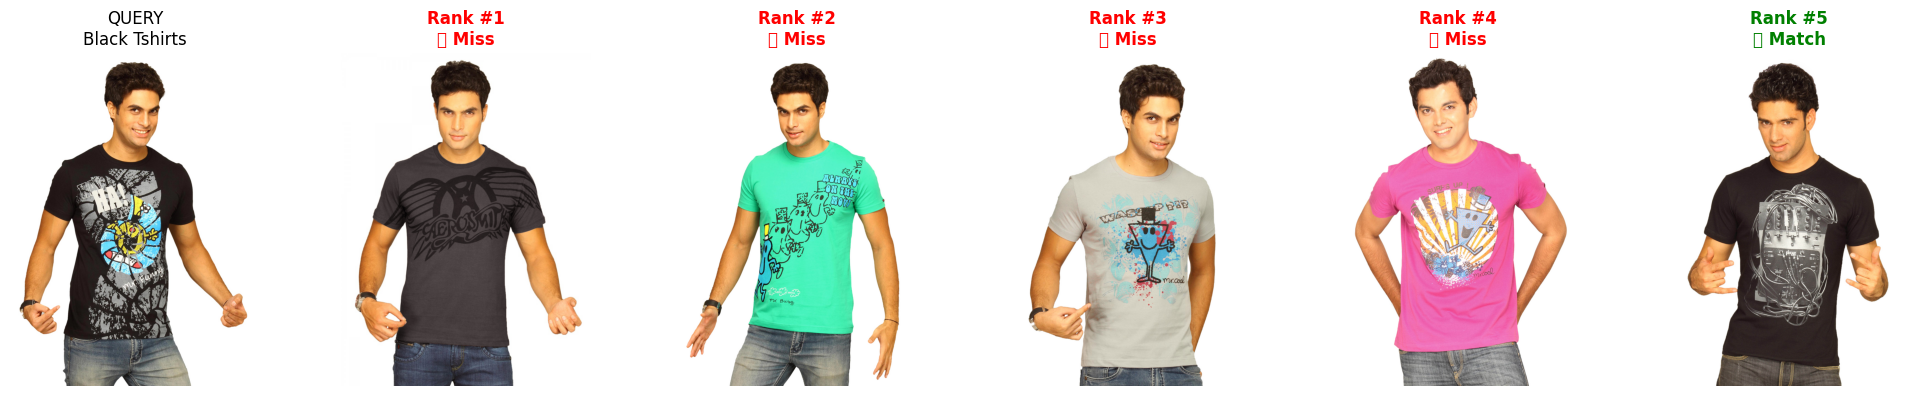

 62%|██████▏   | 13/21 [00:07<00:01,  4.02it/s]

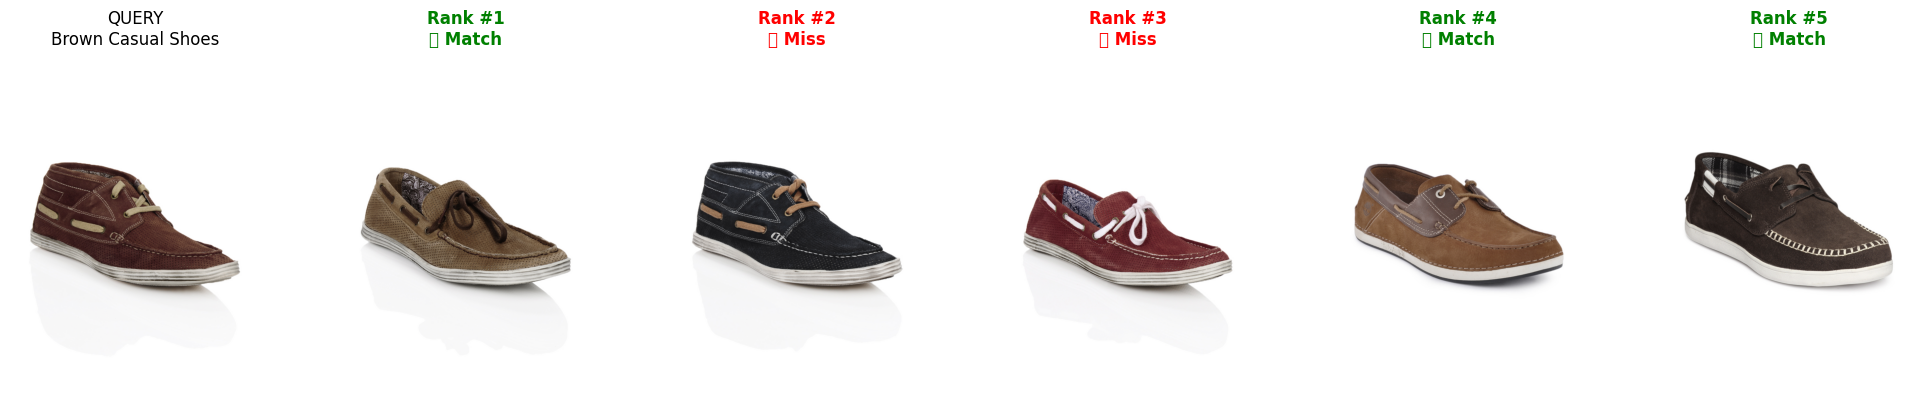

 71%|███████▏  | 15/21 [00:09<00:02,  2.19it/s]

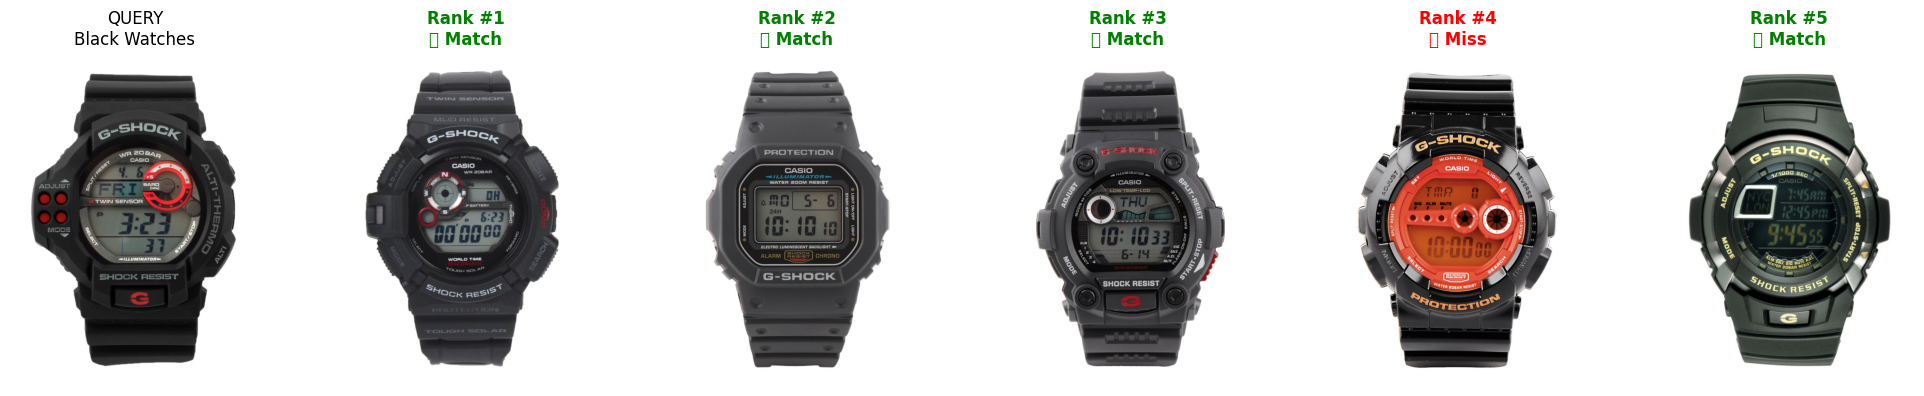

 76%|███████▌  | 16/21 [00:10<00:03,  1.41it/s]

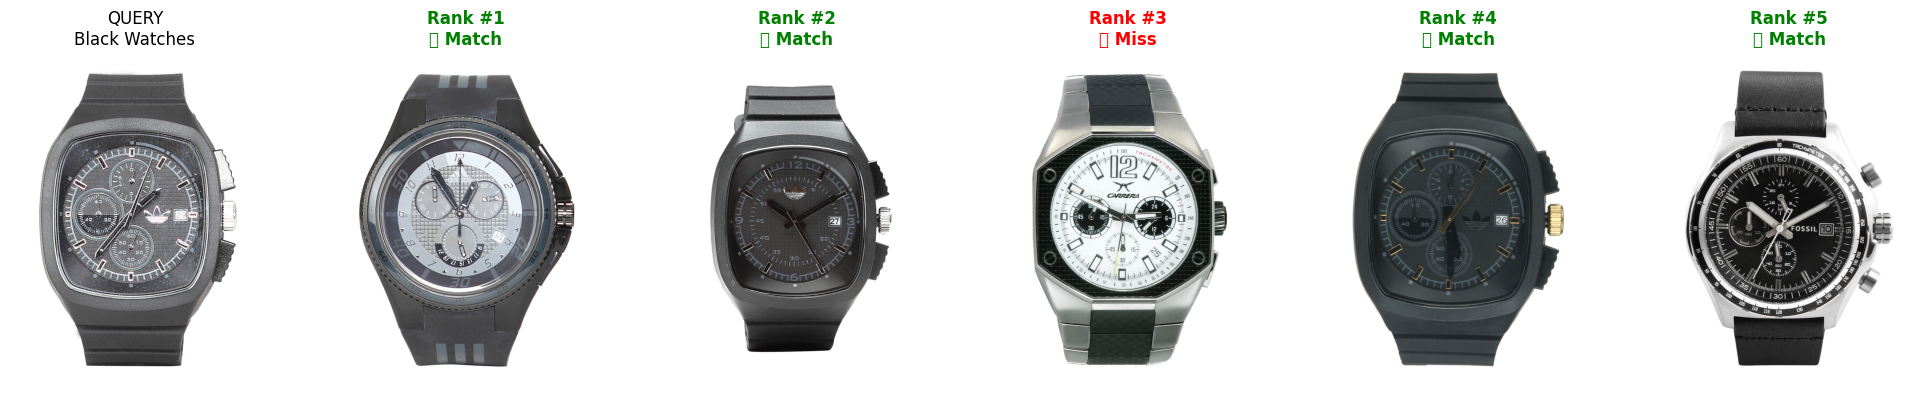

 86%|████████▌ | 18/21 [00:12<00:02,  1.18it/s]

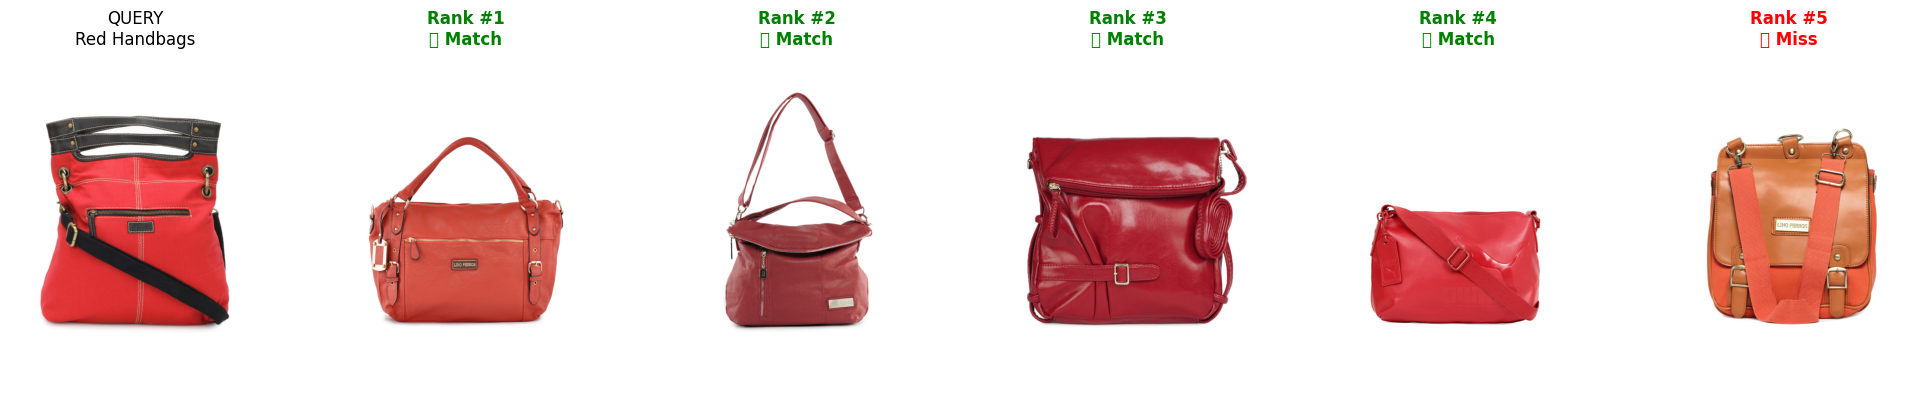

100%|██████████| 21/21 [00:14<00:00,  1.44it/s]


📊 FINAL RESULTS (N=21)
Precision@10: 0.6000
Recall@10:    0.0143
MRR:          0.7032


In [7]:
# Initialize Engine
engine = SearchEngine(
    index_path="../artifacts/fashion.index", 
    metadata_path="../artifacts/clean_metadata.pkl" )

metrics = {'p10': [], 'recall10': [], 'mrr': [], 'latency': []}

print("🚀 Starting Evaluation...")

# Loop through test set
for query in tqdm(test_queries):
    
    # 1. Run Search
    # Note: We ask for k=11 because we might find the query image itself at Rank 1
    results = engine.search_by_image(f"../{query['image_path']}", top_k=11)
    
    # 2. Extract IDs
    retrieved_ids = [r['id'] for r in results]
    
    # 3. Remove Self-Match (The query image should not count as a result)
    if query['query_id'] in retrieved_ids:
        retrieved_ids.remove(query['query_id'])
    
    # Keep top 10
    retrieved_ids = retrieved_ids[:10]
    
    # 4. Calculate Metrics
    p10 = SearchMetrics.precision_at_k(retrieved_ids, query['relevant_ids'], k=10)
    r10 = SearchMetrics.recall_at_k(retrieved_ids, query['relevant_ids'], k=10)
    mrr = SearchMetrics.reciprocal_rank(retrieved_ids, query['relevant_ids'])
    
    metrics['p10'].append(p10)
    metrics['recall10'].append(r10)
    metrics['mrr'].append(mrr)
    
    # 5. VISUALIZE (Optional: Show every 5th result to keep notebook clean)
    if np.random.rand() < 0.2: # Show 20% of queries
        visualize_search(query, retrieved_ids, None, df)

# Final Scores
print("\n" + "="*40)
print(f"📊 FINAL RESULTS (N={len(test_queries)})")
print("="*40)
print(f"Precision@10: {np.mean(metrics['p10']):.4f}")
print(f"Recall@10:    {np.mean(metrics['recall10']):.4f}")
print(f"MRR:          {np.mean(metrics['mrr']):.4f}")

C:\Users\AMAND\AppData\Local\Temp\ipykernel_19752\2569547207.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Metric', y='Score', palette='viridis')


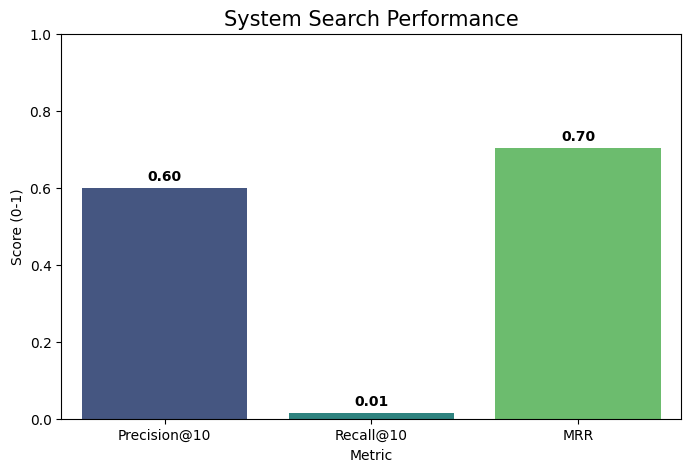

In [8]:
# Plotting the Results
results_df = pd.DataFrame({
    'Metric': ['Precision@10', 'Recall@10', 'MRR'],
    'Score': [np.mean(metrics['p10']), np.mean(metrics['recall10']), np.mean(metrics['mrr'])]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x='Metric', y='Score', palette='viridis')
plt.ylim(0, 1.0)
plt.title("System Search Performance", fontsize=15)
plt.ylabel("Score (0-1)")
for i, v in enumerate(results_df['Score']):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')
plt.show()